# DCGAN on MNIST

Interactive, cell-by-cell version of `tools/train.py` for the CA-2 project.
Run cells top to bottom in VS Code's Jupyter extension (select the Python kernel that has `torch`/`torchvision` installed).

See `NOTES.md` in the repo root for the full line-by-line explanation of this code.

In [1]:
import os
import sys
import yaml
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.optim import Adam
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

# Make the repo root importable (this notebook lives in notebooks/)
sys.path.append(os.path.abspath('..'))

from model.dcgan import Generator, Discriminator
from dataset.mnist_dataset import MnistDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


/home/rudra/dev/playground/DLCA2/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load config

In [2]:
config_path = '../config/mnist.yaml'
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

dataset_config = config['dataset_params']
model_config = config['model_params']
train_config = config['train_params']
config

{'dataset_params': {'im_path': 'data',
  'im_ext': 'png',
  'im_channels': 1,
  'im_size': 28,
  'name': 'mnist'},
 'model_params': {'latent_dim': 100,
  'generator_channels': [512, 256, 128],
  'generator_kernels': [4, 4, 4, 4],
  'generator_strides': [2, 2, 2, 2],
  'generator_paddings': [1, 1, 1, 1],
  'generator_output_paddings': [1, 1, 0, 0],
  'discriminator_channels': [128, 256, 512],
  'discriminator_kernels': [4, 4, 4, 4],
  'discriminator_strides': [2, 2, 2, 2],
  'discriminator_paddings': [1, 1, 1, 1]},
 'train_params': {'task_name': 'task_mnist',
  'batch_size': 128,
  'num_epochs': 20,
  'num_samples': 100,
  'num_grid_rows': 10,
  'save_sample_steps': 100,
  'lr': 0.0005,
  'ckpt_name': 'mnist_ckpt.pth'}}

## 2. Dataset and DataLoader

MNIST auto-downloads into `../data/` the first time this cell runs (no manual data prep needed).

In [3]:
im_dataset = MnistDataset(split='train',
                           im_path='../' + dataset_config['im_path'],
                           im_size=dataset_config['im_size'],
                           im_channels=dataset_config['im_channels'],
                           im_ext=dataset_config['im_ext'])

mnist_loader = DataLoader(im_dataset, batch_size=train_config['batch_size'], shuffle=True)
len(im_dataset)

Found 60000 images for split train


60000

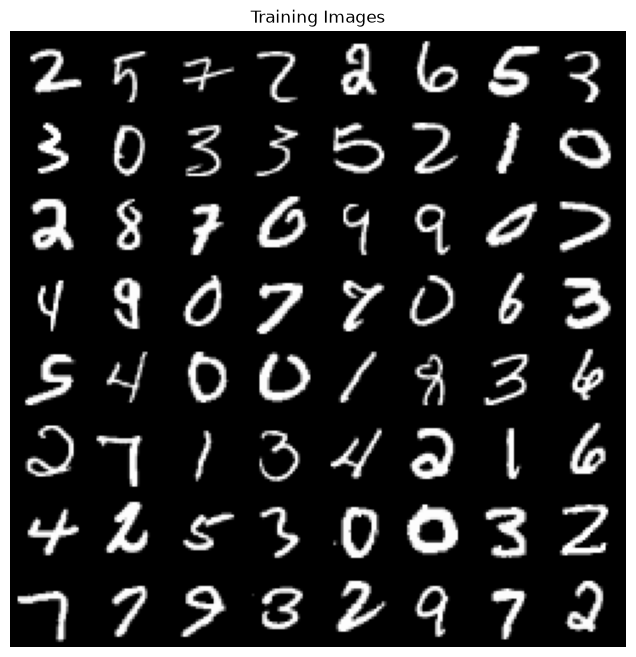

In [4]:
# Plot a batch of real training images
real_batch = next(iter(mnist_loader))
plt.figure(figsize=(8, 8))
plt.axis('off')
plt.title('Training Images')
grid = make_grid((real_batch[:64] + 1) / 2, padding=2)
plt.imshow(np.transpose(grid.cpu(), (1, 2, 0)))
plt.show()

## 3. Build Generator and Discriminator

In [5]:
generator = Generator(latent_dim=model_config['latent_dim'],
                       im_size=dataset_config['im_size'],
                       im_channels=dataset_config['im_channels'],
                       conv_channels=model_config['generator_channels'],
                       kernels=model_config['generator_kernels'],
                       strides=model_config['generator_strides'],
                       paddings=model_config['generator_paddings'],
                       output_paddings=model_config['generator_output_paddings']).to(device)

discriminator = Discriminator(im_size=dataset_config['im_size'],
                               im_channels=dataset_config['im_channels'],
                               conv_channels=model_config['discriminator_channels'],
                               kernels=model_config['discriminator_kernels'],
                               strides=model_config['discriminator_strides'],
                               paddings=model_config['discriminator_paddings']).to(device)

generator.train()
discriminator.train()
print(generator)
print(discriminator)

Generator(
  (layers): ModuleList(
    (0): Sequential(
      (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), output_padding=(1, 1), bias=False)
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), output_padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): Sequential(
      (0): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): Identity()
      (2): Tanh()
    )
  )
)
Discriminator(
  (layers): ModuleList

## 4. Optimizers and loss

In [6]:
optimizer_generator = Adam(generator.parameters(), lr=train_config['lr'], betas=(0.5, 0.999))
optimizer_discriminator = Adam(discriminator.parameters(), lr=train_config['lr'], betas=(0.5, 0.999))
criterion = torch.nn.BCEWithLogitsLoss()

task_dir = '../' + train_config['task_name']
samples_dir = os.path.join(task_dir, 'samples')
os.makedirs(samples_dir, exist_ok=True)

def infer(generated_sample_count, generator):
    with torch.no_grad():
        fake_im_noise = torch.randn((train_config['num_samples'], model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        fake_ims = (fake_ims + 1) / 2
        grid = make_grid(fake_ims, nrow=train_config['num_grid_rows'])
        img = torchvision.transforms.ToPILImage()(grid)
        img.save(os.path.join(samples_dir, '{}.png'.format(generated_sample_count)))
        return img

## 5. Training loop

Standard alternating GAN update: discriminator step on real + detached-fake, then generator step through a fresh fake batch. Saves a sample grid every `save_sample_steps` steps and a checkpoint every epoch — see `NOTES.md` §4.3 for the line-by-line explanation.

In [7]:
steps = 0
generated_sample_count = 0

for epoch_idx in range(train_config['num_epochs']):
    generator_losses = []
    discriminator_losses = []
    mean_real_dis_preds = []
    mean_fake_dis_preds = []
    for im in tqdm(mnist_loader):
        real_ims = im.float().to(device)
        batch_size = real_ims.shape[0]

        # --- Discriminator step ---
        optimizer_discriminator.zero_grad()
        fake_im_noise = torch.randn((batch_size, model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        real_label = torch.ones((batch_size, 1), device=device)
        fake_label = torch.zeros((batch_size, 1), device=device)

        disc_real_pred = discriminator(real_ims)
        disc_fake_pred = discriminator(fake_ims.detach())
        disc_real_loss = criterion(disc_real_pred.reshape(-1), real_label.reshape(-1))
        mean_real_dis_preds.append(torch.nn.Sigmoid()(disc_real_pred).mean().item())
        disc_fake_loss = criterion(disc_fake_pred.reshape(-1), fake_label.reshape(-1))
        mean_fake_dis_preds.append(torch.nn.Sigmoid()(disc_fake_pred).mean().item())
        disc_loss = (disc_real_loss + disc_fake_loss) / 2
        disc_loss.backward()
        optimizer_discriminator.step()

        # --- Generator step ---
        optimizer_generator.zero_grad()
        fake_im_noise = torch.randn((batch_size, model_config['latent_dim']), device=device)
        fake_ims = generator(fake_im_noise)
        disc_fake_pred = discriminator(fake_ims)
        gen_fake_loss = criterion(disc_fake_pred.reshape(-1), real_label.reshape(-1))
        gen_fake_loss.backward()
        optimizer_generator.step()

        generator_losses.append(gen_fake_loss.item())
        discriminator_losses.append(disc_loss.item())

        if steps % train_config['save_sample_steps'] == 0:
            generator.eval()
            infer(generated_sample_count, generator)
            generated_sample_count += 1
            generator.train()
        steps += 1

    print('Finished epoch:{} | Generator Loss : {:.4f} | Discriminator Loss : {:.4f} | '
          'Discriminator real pred : {:.4f} | Discriminator fake pred : {:.4f}'.format(
        epoch_idx + 1,
        np.mean(generator_losses),
        np.mean(discriminator_losses),
        np.mean(mean_real_dis_preds),
        np.mean(mean_fake_dis_preds),
    ))
    torch.save(generator.state_dict(), os.path.join(task_dir, 'generator_' + train_config['ckpt_name']))
    torch.save(discriminator.state_dict(), os.path.join(task_dir, 'discriminator_' + train_config['ckpt_name']))

print('Done Training ...')

100%|██████████| 469/469 [00:19<00:00, 24.22it/s]


Finished epoch:1 | Generator Loss : 2.7435 | Discriminator Loss : 0.4057 | Discriminator real pred : 0.7315 | Discriminator fake pred : 0.2670


100%|██████████| 469/469 [00:18<00:00, 25.42it/s]


Finished epoch:2 | Generator Loss : 1.8954 | Discriminator Loss : 0.3922 | Discriminator real pred : 0.7240 | Discriminator fake pred : 0.2743


100%|██████████| 469/469 [00:18<00:00, 25.35it/s]


...

Finished epoch:18 | Generator Loss : 4.3885 | Discriminator Loss : 0.1183 | Discriminator real pred : 0.9189 | Discriminator fake pred : 0.0815


100%|██████████| 469/469 [00:19<00:00, 24.51it/s]


Finished epoch:19 | Generator Loss : 4.5509 | Discriminator Loss : 0.1054 | Discriminator real pred : 0.9298 | Discriminator fake pred : 0.0700


100%|██████████| 469/469 [00:19<00:00, 24.56it/s]

Finished epoch:20 | Generator Loss : 4.3718 | Discriminator Loss : 0.1130 | Discriminator real pred : 0.9218 | Discriminator fake pred : 0.0779
Done Training ...


## 6. Inspect results

Compare the first saved sample grid (near-random noise) against the last one (trained digits).

Saved sample grids: 94


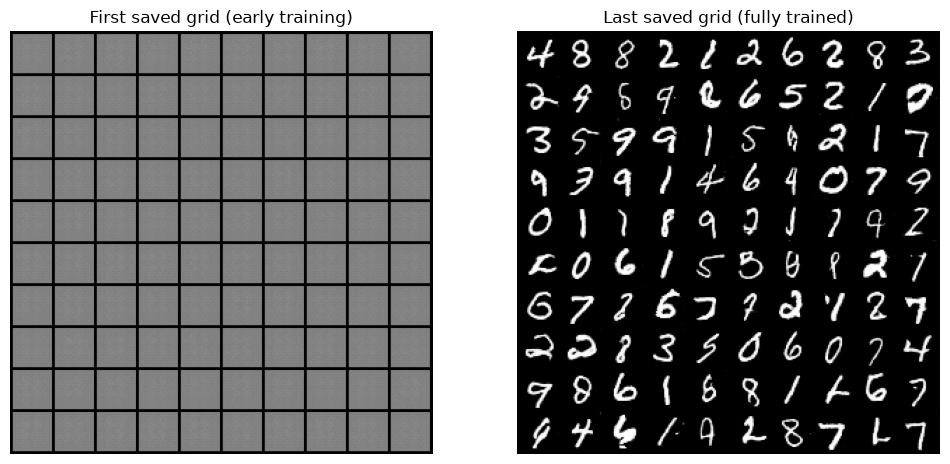

In [8]:
img_list = sorted(os.listdir(samples_dir), key=lambda x: int(x.split('.')[0]))
print('Saved sample grids:', len(img_list))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(plt.imread(os.path.join(samples_dir, img_list[0])))
axes[0].set_title('First saved grid (early training)')
axes[0].axis('off')
axes[1].imshow(plt.imread(os.path.join(samples_dir, img_list[-1])))
axes[1].set_title('Last saved grid (fully trained)')
axes[1].axis('off')
plt.show()

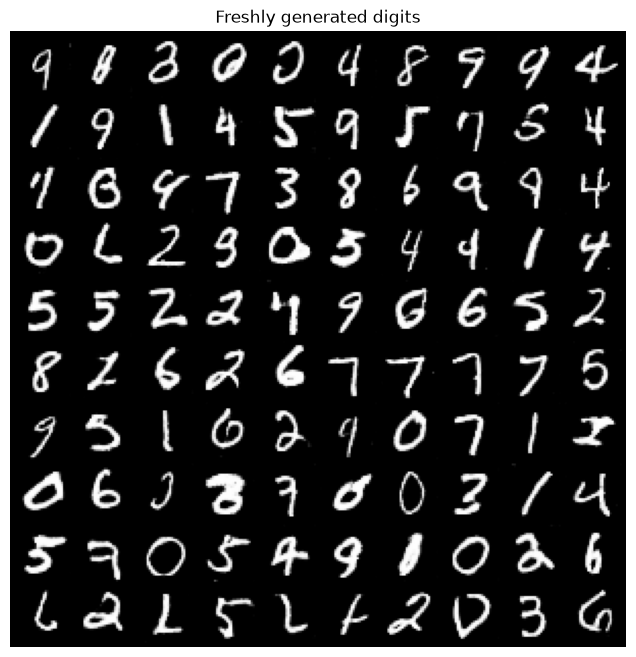

In [9]:
# Generate a fresh batch of digits from the trained generator
generator.eval()
img = infer(generated_sample_count, generator)
generated_sample_count += 1
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')
plt.title('Freshly generated digits')
plt.show()